# EduPro: learner demographics and enrollment behavior
Reproducible descriptive analysis of the supplied workbook. Each numbered step
contains executable Python and displays its output in the companion notebook.
A transaction is used as an enrollment proxy; it does not prove attendance,
completion, learning outcomes, or current platform activity.

In [1]:
# Step 1 — Imports and reproducible output folders
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image
from data_utils import load_data, segment_summary, demand_summary, preference, AGE_LABELS, LEVEL_ORDER
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
OUT = Path('outputs')
TABLES = OUT/'tables'; FIGS = OUT/'figures'
TABLES.mkdir(parents=True,exist_ok=True); FIGS.mkdir(parents=True,exist_ok=True)
sns.set_theme(style='whitegrid', palette='colorblind', font_scale=1.05)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':170,'axes.spines.top':False,'axes.spines.right':False})

def save_table(frame,name):
    frame.to_csv(TABLES/f'{name}.csv')
    display(frame)

def show_chart(name):
    plt.tight_layout()
    path = FIGS/f'{name}.png'
    plt.savefig(path,bbox_inches='tight'); plt.close()
    display(Image(filename=str(path)))
print('Output directories ready.')

Output directories ready.


## Step 2 — Load, audit, and integrate
data_utils.load_data reads only needed fields (not names/emails), trims strings,
rejects missing required values, duplicate primary keys, invalid ages/dates,
orphan foreign keys and unexpected course levels, then validates many-to-one
joins. It never silently deletes or repairs records. See data_utils.py for the
complete implementation. Teachers and financial fields are outside scope.

In [2]:
users, courses, transactions, enrollments, audit = load_data()
print(f'Users: {len(users):,}; Courses: {len(courses):,}; Transactions: {len(transactions):,}; Joined rows: {len(enrollments):,}')
print(f'Coverage: {transactions.TransactionDate.min():%Y-%m-%d} to {transactions.TransactionDate.max():%Y-%m-%d}')
save_table(audit,'data_quality')
print('Age range:', int(users.Age.min()), 'to', int(users.Age.max()))
print('Personal names and email addresses excluded from analytical outputs.')

Users: 3,000; Courses: 60; Transactions: 10,000; Joined rows: 10,000
Coverage: 2025-01-01 to 2025-12-30


,Check,Value
0,Users required-field missing cells,0
1,Users duplicate primary IDs,0
2,Courses required-field missing cells,0
3,Courses duplicate primary IDs,0
4,Transactions required-field missing cells,0
5,Transactions duplicate primary IDs,0
6,Unmatched UserID,0
7,Unmatched CourseID,0
8,Joined rows,10000
9,Repeated user-course pairs (not deleted),0


Age range: 15 to 35
Personal names and email addresses excluded from analytical outputs.


## Step 3 — Define age bands and KPI denominators
Nonoverlapping integer-age bands: <18, 18–25, 26–35, 36–45, and 46+.
The prompt's “45+” overlaps 36–45, so 46+ is used. No users are older than 35.
Active = at least one recorded transaction anywhere in the supplied period.
Average per registered learner includes zero-enrollment learners if present.
Category popularity index = category enrollments / all enrollments × 100.

In [3]:
learner_counts = enrollments.groupby('UserID').size().reindex(users.UserID,fill_value=0)
active_counts = learner_counts[learner_counts>0].sort_values(ascending=False)
top_n = math.ceil(0.10*len(active_counts))
kpis = pd.DataFrame({'Value': {
    'Registered learners': len(users),
    'Active learners': enrollments.UserID.nunique(),
    'Total enrollments (transaction proxy)': len(enrollments),
    'Distinct learner-course pairs': len(enrollments[['UserID','CourseID']].drop_duplicates()),
    'Catalog courses': len(courses),
    'Participation rate (%)': enrollments.UserID.nunique()/len(users)*100,
    'Mean enrollments per registered learner': len(enrollments)/len(users),
    'Mean enrollments per active learner': len(enrollments)/enrollments.UserID.nunique(),
    'Median enrollments per registered learner': learner_counts.median(),
    'Top 10% active learner enrollment share (%)': active_counts.iloc[:top_n].sum()/len(enrollments)*100,
    'Mean age': users.Age.mean(),
    'Median age': users.Age.median(),
}})
save_table(kpis,'kpis')

,Value
Registered learners,"3,000.00"
Active learners,"3,000.00"
Total enrollments (transaction proxy),"10,000.00"
Distinct learner-course pairs,"10,000.00"
Catalog courses,60.00
Participation rate (%),100.00
Mean enrollments per registered learner,3.33
Mean enrollments per active learner,3.33
Median enrollments per registered learner,1.00
Top 10% active learner enrollment share (%),42.34


## Step 4 — Demographics and age-wise enrollment
Use both counts and rates: a larger enrollment total may simply reflect a
larger learner group. Empty age groups have zero counts and undefined rates.

,RegisteredLearners,ActiveLearners,Enrollments,LearnerSharePct,EnrollmentSharePct,ParticipationRatePct,EnrollmentsPerRegisteredLearner,EnrollmentsPerActiveLearner
AgeGroup,,,,,,,,
<18,433,433,1469,14.43,14.69,100.00,3.39,3.39
18–25,1121,1121,3732,37.37,37.32,100.00,3.33,3.33
26–35,1446,1446,4799,48.20,47.99,100.00,3.32,3.32
36–45,0,0,0,0.00,0.00,NaN,NaN,NaN
46+,0,0,0,0.00,0.00,NaN,NaN,NaN


,RegisteredLearners,ActiveLearners,Enrollments,LearnerSharePct,EnrollmentSharePct,ParticipationRatePct,EnrollmentsPerRegisteredLearner,EnrollmentsPerActiveLearner
Gender,,,,,,,,
Female,1520,1520,5078,50.67,50.78,100.00,3.34,3.34
Male,1480,1480,4922,49.33,49.22,100.00,3.33,3.33


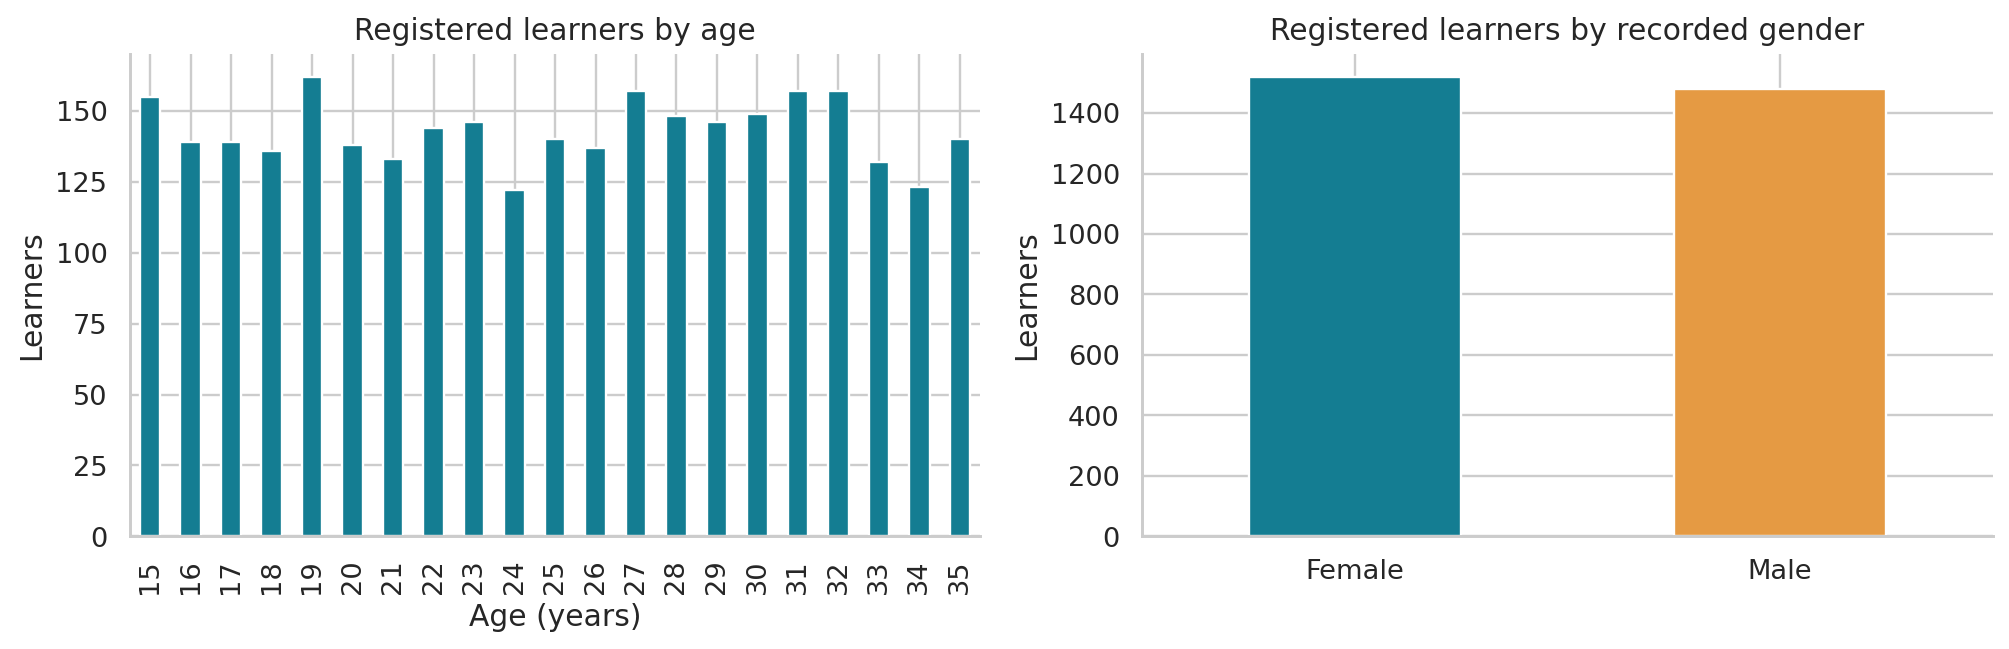

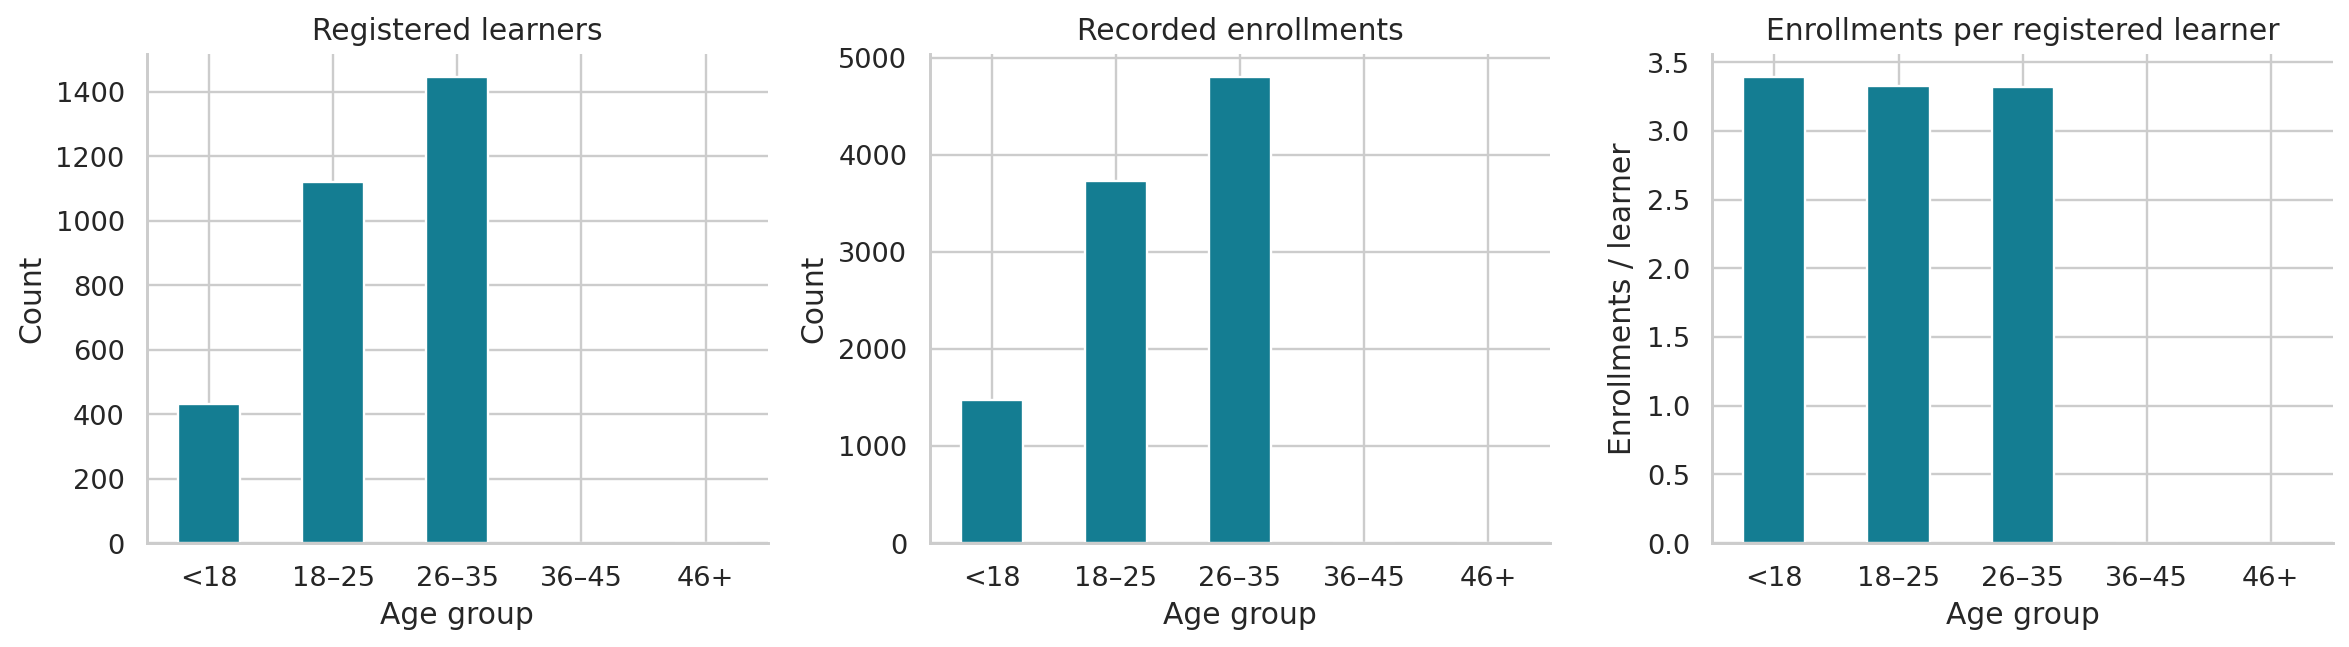

In [4]:
age_summary = segment_summary(users,enrollments,'AgeGroup')
gender_summary = segment_summary(users,enrollments,'Gender')
save_table(age_summary,'age_summary')
save_table(gender_summary,'gender_summary')
fig,axs=plt.subplots(1,2,figsize=(12,4))
users.Age.value_counts().sort_index().plot.bar(ax=axs[0],color='#147D92')
axs[0].set(title='Registered learners by age',xlabel='Age (years)',ylabel='Learners')
users.Gender.value_counts().sort_index().plot.bar(ax=axs[1],color=['#147D92','#E59A43'],rot=0)
axs[1].set(title='Registered learners by recorded gender',xlabel='',ylabel='Learners')
show_chart('01_demographics')
fig,axs=plt.subplots(1,3,figsize=(14,4))
for ax,col,title in zip(axs,['RegisteredLearners','Enrollments','EnrollmentsPerRegisteredLearner'],['Registered learners','Recorded enrollments','Enrollments per registered learner']):
    age_summary[col].plot.bar(ax=ax,color='#147D92',rot=0)
    ax.set(title=title,xlabel='Age group',ylabel='Count' if col!='EnrollmentsPerRegisteredLearner' else 'Enrollments / learner')
show_chart('02_age_participation')

## Step 5 — Course category, type, and level demand
Report enrollment shares alongside catalog supply. A high total is not proof
of stronger preference if more courses of that type/level are offered.

,CatalogCourses,Enrollments,ActiveLearners,EnrollmentSharePct,EnrollmentsPerCatalogCourse
CourseCategory,,,,,
Data Science,5,916,685,9.16,183.20
Finance,5,864,650,8.64,172.80
Web Development,5,844,652,8.44,168.80
Business,5,833,648,8.33,166.60
Project Management,5,829,636,8.29,165.80
Artificial Intelligence,5,829,639,8.29,165.80
Design,5,827,657,8.27,165.40
Cybersecurity,5,819,652,8.19,163.80
Machine Learning,5,819,639,8.19,163.80


,CatalogCourses,Enrollments,ActiveLearners,EnrollmentSharePct,EnrollmentsPerCatalogCourse
CourseType,,,,,
Free,38,6403,2359,64.03,168.50
Paid,22,3597,1605,35.97,163.50


,CatalogCourses,Enrollments,ActiveLearners,EnrollmentSharePct,EnrollmentsPerCatalogCourse
CourseLevel,,,,,
Beginner,21,3573,1596,35.73,170.14
Advanced,21,3475,1608,34.75,165.48
Intermediate,18,2952,1464,29.52,164.00


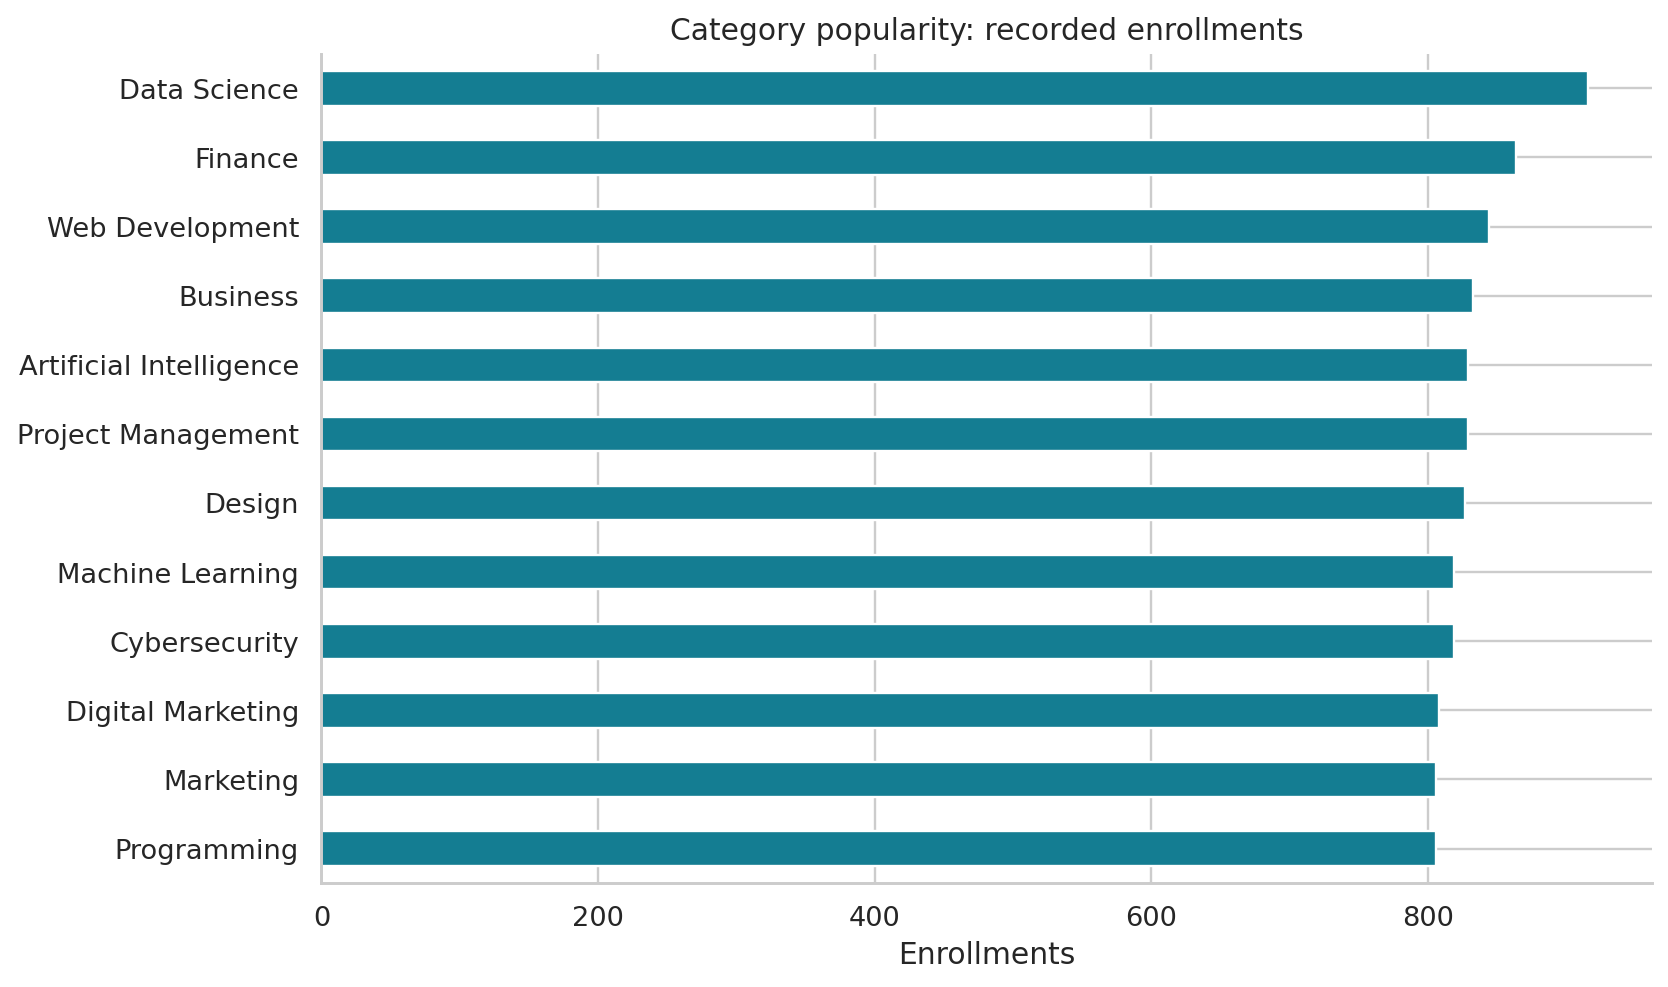

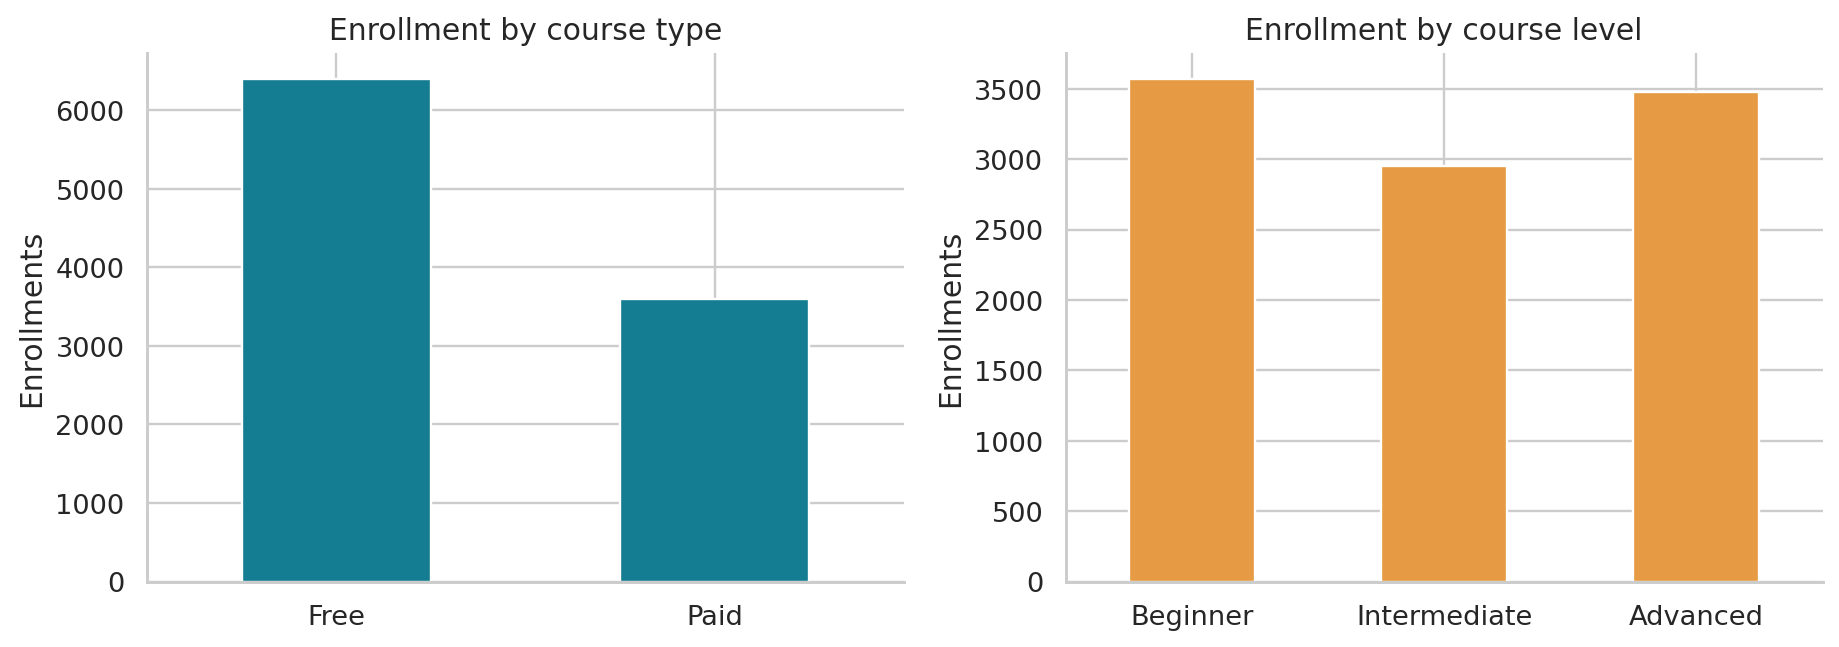

In [5]:
category_summary = demand_summary(enrollments,courses,'CourseCategory')
type_summary = demand_summary(enrollments,courses,'CourseType')
level_summary = demand_summary(enrollments,courses,'CourseLevel')
save_table(category_summary,'category_summary')
save_table(type_summary,'type_summary')
save_table(level_summary,'level_summary')
fig,ax=plt.subplots(figsize=(10,6))
category_summary.Enrollments.sort_values().plot.barh(ax=ax,color='#147D92')
ax.set(title='Category popularity: recorded enrollments',xlabel='Enrollments',ylabel='')
show_chart('03_category_popularity')
fig,axs=plt.subplots(1,2,figsize=(11,4))
type_summary.Enrollments.plot.bar(ax=axs[0],rot=0,color='#147D92')
level_summary.reindex(LEVEL_ORDER).Enrollments.plot.bar(ax=axs[1],rot=0,color='#E59A43')
axs[0].set(title='Enrollment by course type',ylabel='Enrollments',xlabel='')
axs[1].set(title='Enrollment by course level',ylabel='Enrollments',xlabel='')
show_chart('04_type_level')

## Step 6 — Age × category preferences
Row-normalized percentages compare within-group distributions. Empty age
groups are shown as N/A, not falsely interpreted as zero preference.

CourseCategory,Artificial Intelligence,Business,Cybersecurity,Data Science,Design,Digital Marketing,Finance,Machine Learning,Marketing,Programming,Project Management,Web Development
AgeGroup,,,,,,,,,,,,
<18,129,120,121,114,120,127,136,120,126,109,115,132
18–25,317,307,307,343,311,296,297,305,313,305,296,335
26–35,383,406,391,459,396,385,431,394,367,392,418,377
36–45,0,0,0,0,0,0,0,0,0,0,0,0
46+,0,0,0,0,0,0,0,0,0,0,0,0


CourseCategory,Artificial Intelligence,Business,Cybersecurity,Data Science,Design,Digital Marketing,Finance,Machine Learning,Marketing,Programming,Project Management,Web Development
AgeGroup,,,,,,,,,,,,
<18,8.78,8.17,8.24,7.76,8.17,8.65,9.26,8.17,8.58,7.42,7.83,8.99
18–25,8.49,8.23,8.23,9.19,8.33,7.93,7.96,8.17,8.39,8.17,7.93,8.98
26–35,7.98,8.46,8.15,9.56,8.25,8.02,8.98,8.21,7.65,8.17,8.71,7.86
36–45,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
46+,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


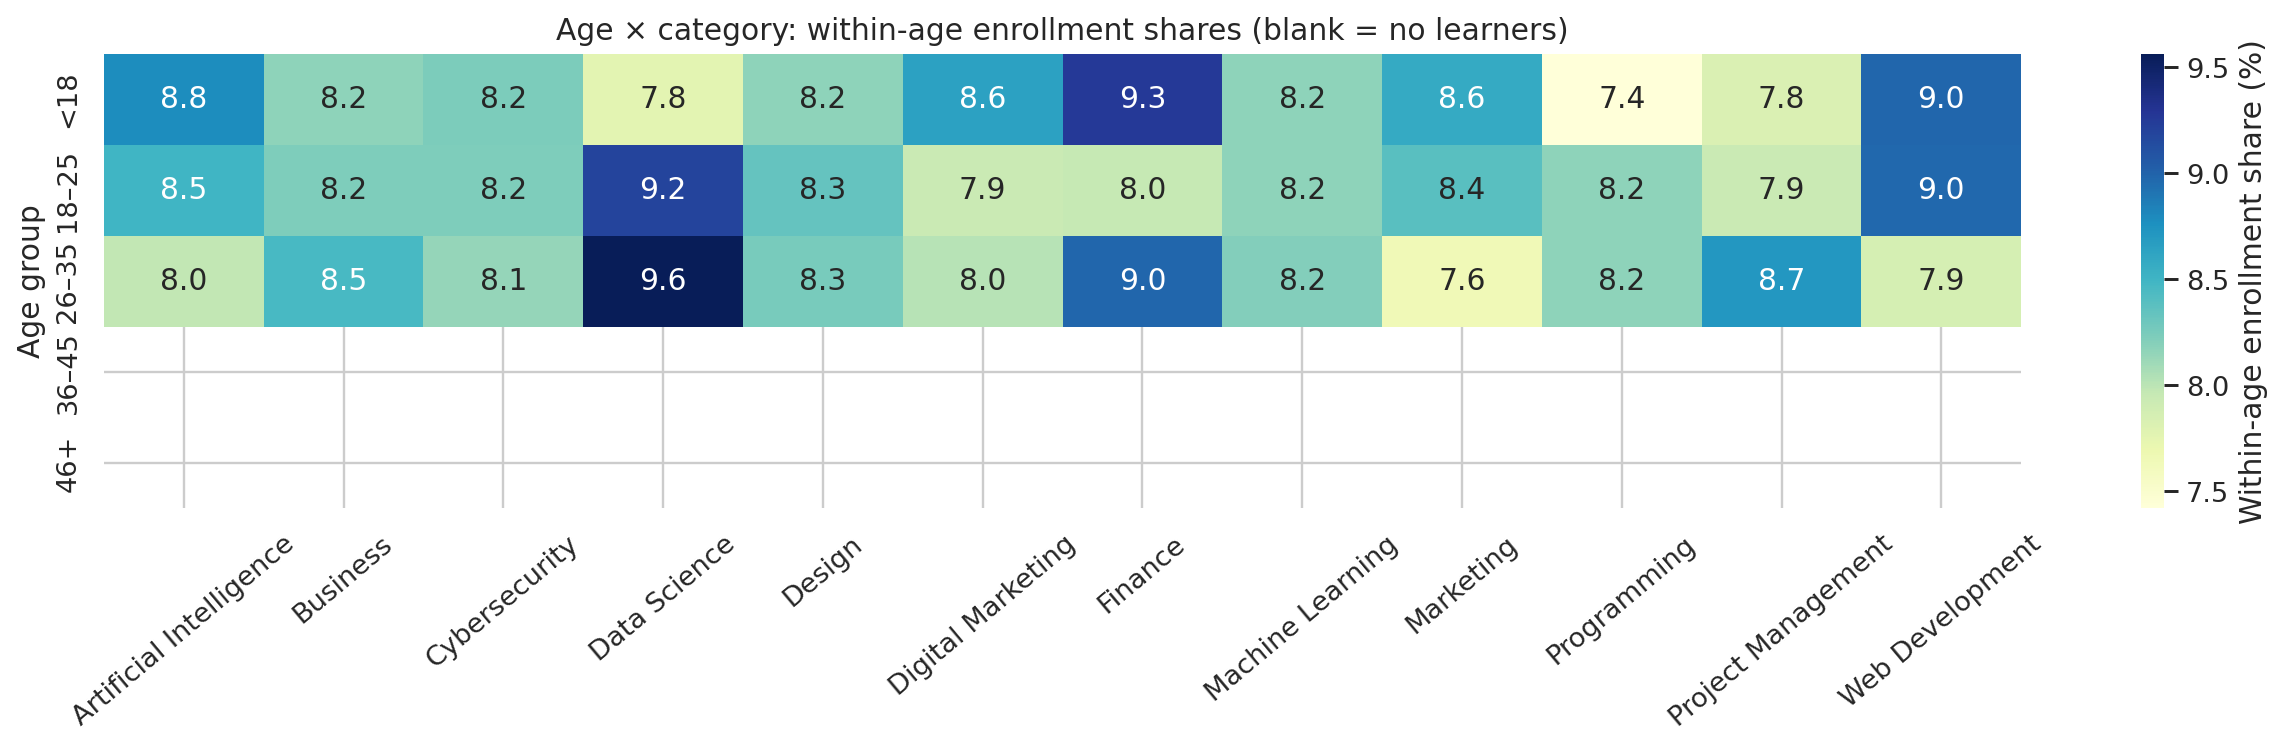

In [6]:
age_cat_counts, age_cat_pct = preference(enrollments,'AgeGroup','CourseCategory',AGE_LABELS)
save_table(age_cat_counts,'age_category_counts')
save_table(age_cat_pct,'age_category_percent')
fig,ax=plt.subplots(figsize=(15,4.6))
sns.heatmap(age_cat_pct,annot=True,fmt='.1f',cmap='YlGnBu',mask=age_cat_pct.isna(),ax=ax,cbar_kws={'label':'Within-age enrollment share (%)'})
ax.set(title='Age × category: within-age enrollment shares (blank = no learners)',xlabel='',ylabel='Age group')
ax.tick_params(axis='x',rotation=40)
show_chart('05_age_category_heatmap')

## Step 7 — Gender × category and level; age × level
Recorded gender has only Female/Male labels. This does not establish that the
platform fully represents gender diversity. Shares describe enrollments, not
unique learners per course choice (a learner can select multiple categories).

CourseCategory,Artificial Intelligence,Business,Cybersecurity,Data Science,Design,Digital Marketing,Finance,Machine Learning,Marketing,Programming,Project Management,Web Development
Gender,,,,,,,,,,,,
Female,413,418,430,479,424,417,451,403,385,420,425,413
Male,416,415,389,437,403,391,413,416,421,386,404,431


CourseCategory,Artificial Intelligence,Business,Cybersecurity,Data Science,Design,Digital Marketing,Finance,Machine Learning,Marketing,Programming,Project Management,Web Development
Gender,,,,,,,,,,,,
Female,8.13,8.23,8.47,9.43,8.35,8.21,8.88,7.94,7.58,8.27,8.37,8.13
Male,8.45,8.43,7.90,8.88,8.19,7.94,8.39,8.45,8.55,7.84,8.21,8.76


CourseLevel,Beginner,Intermediate,Advanced
Gender,,,
Female,1811,1509,1758
Male,1762,1443,1717


CourseLevel,Beginner,Intermediate,Advanced
Gender,,,
Female,35.66,29.72,34.62
Male,35.80,29.32,34.88


CourseLevel,Beginner,Intermediate,Advanced
AgeGroup,,,
<18,501,434,534
18–25,1345,1087,1300
26–35,1727,1431,1641
36–45,0,0,0
46+,0,0,0


CourseLevel,Beginner,Intermediate,Advanced
AgeGroup,,,
<18,34.10,29.54,36.35
18–25,36.04,29.13,34.83
26–35,35.99,29.82,34.19
36–45,NaN,NaN,NaN
46+,NaN,NaN,NaN


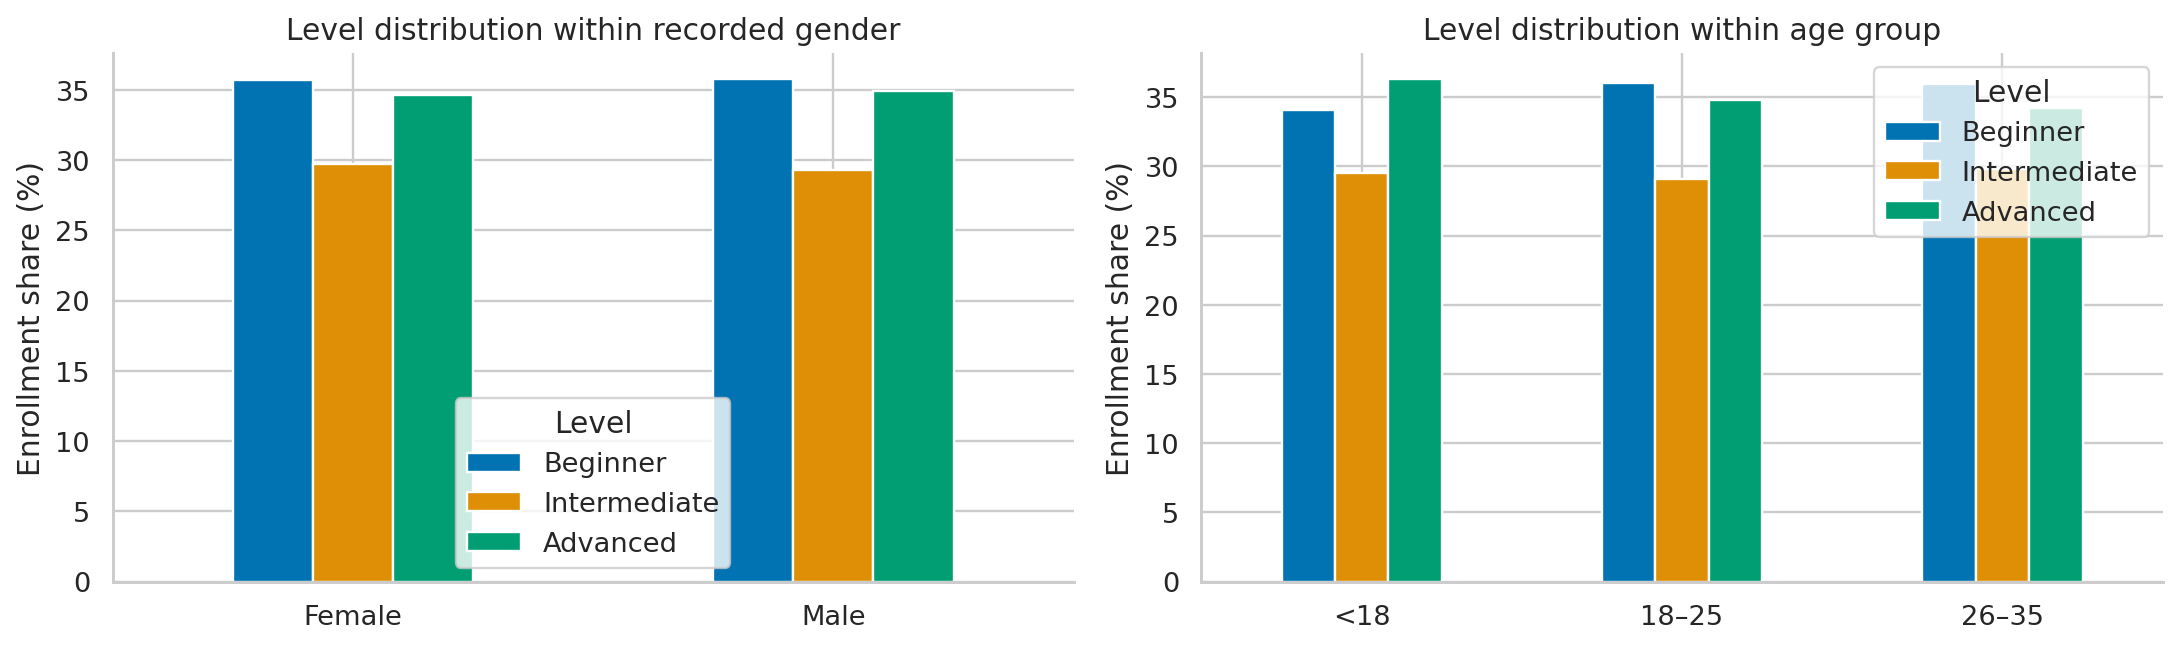

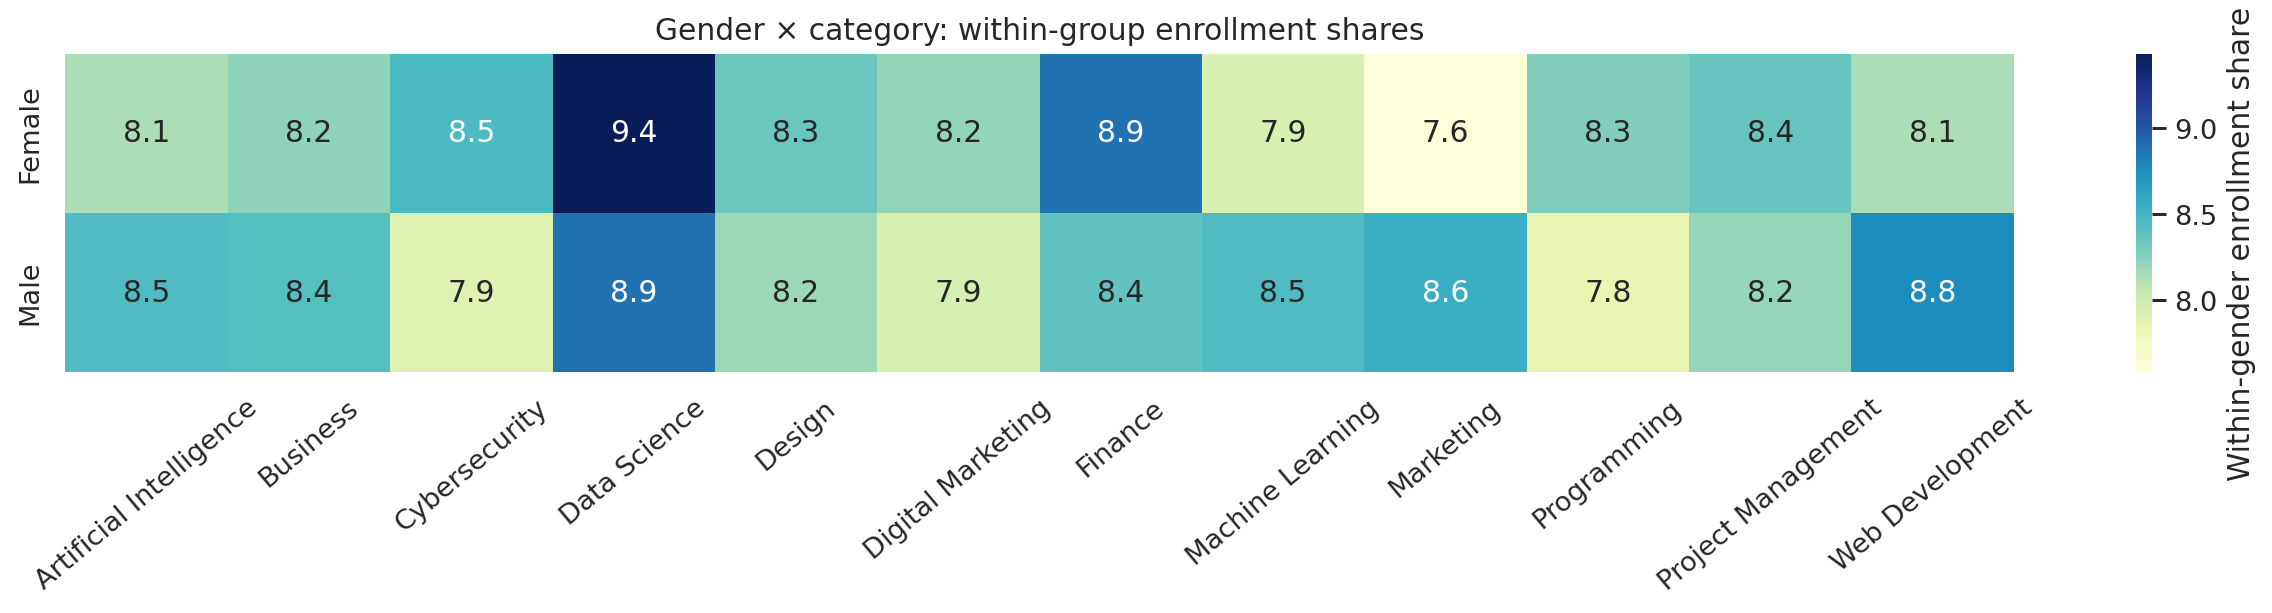

Largest absolute Female–Male category-share gap (percentage points):


,AbsoluteGapPP
CourseCategory,
Marketing,0.97
Web Development,0.62
Cybersecurity,0.56
Data Science,0.55
Machine Learning,0.52


In [7]:
gender_cat_counts, gender_cat_pct = preference(enrollments,'Gender','CourseCategory')
gender_level_counts, gender_level_pct = preference(enrollments,'Gender','CourseLevel',col_order=LEVEL_ORDER)
age_level_counts, age_level_pct = preference(enrollments,'AgeGroup','CourseLevel',AGE_LABELS,LEVEL_ORDER)
for name, table in [('gender_category_counts',gender_cat_counts),('gender_category_percent',gender_cat_pct),('gender_level_counts',gender_level_counts),('gender_level_percent',gender_level_pct),('age_level_counts',age_level_counts),('age_level_percent',age_level_pct)]:
    save_table(table,name)
fig,axs=plt.subplots(1,2,figsize=(13,4))
gender_level_pct.plot.bar(ax=axs[0],rot=0)
axs[0].set(title='Level distribution within recorded gender',ylabel='Enrollment share (%)',xlabel='')
age_level_pct.dropna(how='all').plot.bar(ax=axs[1],rot=0)
axs[1].set(title='Level distribution within age group',ylabel='Enrollment share (%)',xlabel='')
axs[0].legend(title='Level'); axs[1].legend(title='Level')
show_chart('06_demographics_level')
fig,ax=plt.subplots(figsize=(15,3.8))
sns.heatmap(gender_cat_pct,annot=True,fmt='.1f',cmap='YlGnBu',ax=ax,cbar_kws={'label':'Within-gender enrollment share (%)'})
ax.set(title='Gender × category: within-group enrollment shares',xlabel='',ylabel='')
ax.tick_params(axis='x',rotation=40)
show_chart('07_gender_category_heatmap')
print('Largest absolute Female–Male category-share gap (percentage points):')
gaps=gender_cat_pct.loc['Female'].sub(gender_cat_pct.loc['Male']).abs().sort_values(ascending=False)
display(gaps.head().to_frame('AbsoluteGapPP'))
gaps.rename('AbsoluteGapPP').to_csv(TABLES/'gender_category_gap_pp.csv')

## Step 8 — Beginner-course and advanced-course selection
“Beginner” means the course's recorded level, NOT a verified learner skill.
The same learner can take beginner and advanced courses. We have no skill,
intention, completion or prior-experience fields and cannot infer progression.
Use recorded CourseLevel even if course titles appear inconsistent.

CourseType,Free,Paid
CourseLevel,,
Beginner,2395,1178
Intermediate,2003,949
Advanced,2005,1470


CourseType,Free,Paid
CourseLevel,,
Beginner,67.03,32.97
Intermediate,67.85,32.15
Advanced,57.70,42.30


CourseType,Free,Paid
CourseLevel,,
Beginner,14,7
Intermediate,12,6
Advanced,12,9


CourseType,Free,Paid
CourseLevel,,
Beginner,171.07,168.29
Intermediate,166.92,158.17
Advanced,167.08,163.33


,Enrollments,UniqueLearnersSelectingLevel,MeanThisLevelEnrollmentsPerSelectingLearner,MeanAllLevelEnrollmentsForSelectingLearners
CourseLevel,,,,
Beginner,3573,1596,2.24,5.11
Intermediate,2952,1464,2.02,5.39
Advanced,3475,1608,2.16,5.07


Learners selecting BOTH beginner and advanced courses: 752


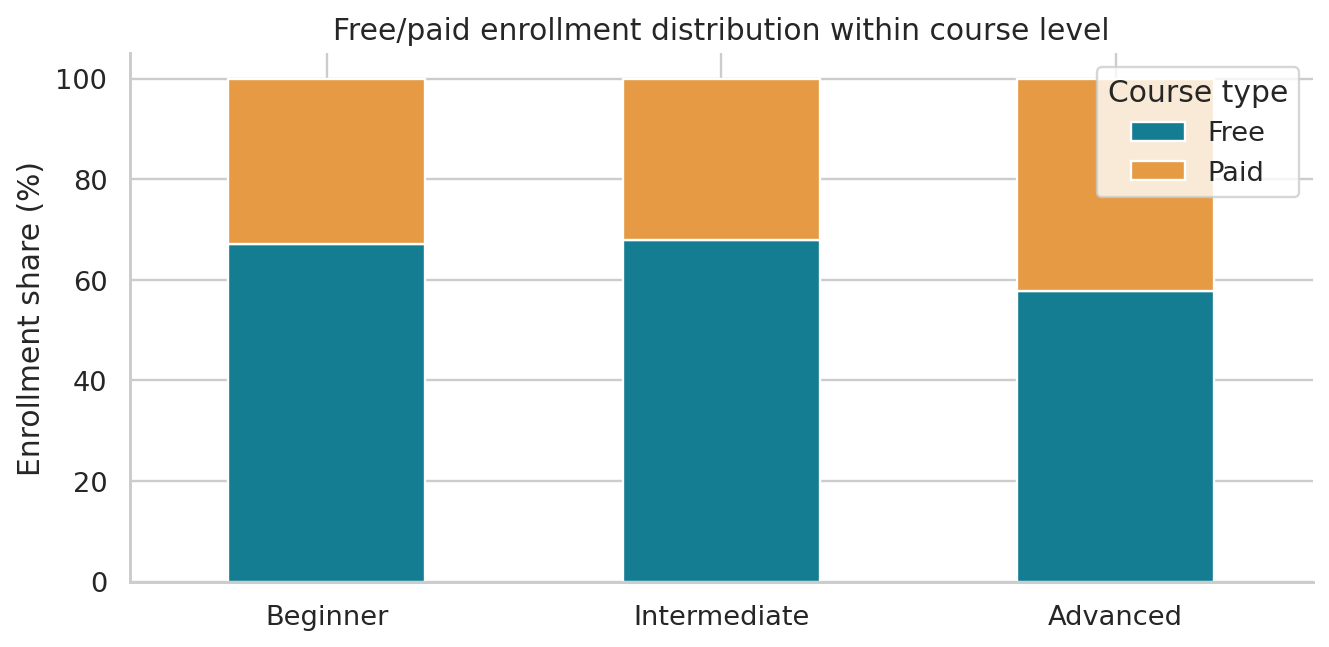

Title/metadata review example:


,CourseName,CourseLevel
3,Advanced Python,Beginner


In [8]:
level_type_counts, level_type_pct = preference(enrollments,'CourseLevel','CourseType',LEVEL_ORDER,['Free','Paid'])
save_table(level_type_counts,'level_type_counts')
save_table(level_type_pct,'level_type_percent')
level_type_supply = pd.crosstab(courses.CourseLevel,courses.CourseType).reindex(index=LEVEL_ORDER,columns=['Free','Paid'],fill_value=0)
save_table(level_type_supply,'level_type_catalog_supply')
normalized_level_type = level_type_counts / level_type_supply.replace(0,np.nan)
save_table(normalized_level_type,'level_type_enrollments_per_catalog_course')
level_cohorts=[]
for level in LEVEL_ORDER:
    selected=enrollments.loc[enrollments.CourseLevel.eq(level)]
    ids=selected.UserID.unique()
    level_cohorts.append({'CourseLevel':level,'Enrollments':len(selected),'UniqueLearnersSelectingLevel':len(ids),
        'MeanThisLevelEnrollmentsPerSelectingLearner':len(selected)/len(ids),
        'MeanAllLevelEnrollmentsForSelectingLearners':learner_counts.loc[ids].mean()})
level_cohorts=pd.DataFrame(level_cohorts).set_index('CourseLevel')
save_table(level_cohorts,'level_selection_cohorts')
beginner_ids=set(enrollments.loc[enrollments.CourseLevel.eq('Beginner'),'UserID'])
advanced_ids=set(enrollments.loc[enrollments.CourseLevel.eq('Advanced'),'UserID'])
print(f'Learners selecting BOTH beginner and advanced courses: {len(beginner_ids & advanced_ids):,}')
fig,ax=plt.subplots(figsize=(8,4))
level_type_pct.plot.bar(stacked=True,ax=ax,rot=0,color=['#147D92','#E59A43'])
ax.set(title='Free/paid enrollment distribution within course level',ylabel='Enrollment share (%)',xlabel='')
ax.legend(title='Course type')
show_chart('08_level_type')
print('Title/metadata review example:')
display(courses.loc[courses.CourseName.str.contains('Advanced',case=False),['CourseName','CourseLevel']])

## Step 9 — Enrollment concentration and individual activity
Top 10% = ceil(10% × active learners), ranked by enrollment count. Ties at
the cutoff do not affect the enrollment share because tied counts are equal.
Aggregate outputs avoid exporting individual identifiers.

,Learners,ShareOfLearnersPct
EnrollmentsPerLearner,,
1,1620,54.00
2,612,20.40
3,186,6.20
4,128,4.27
9,1,0.03
10,4,0.13
11,31,1.03
12,72,2.40
13,122,4.07


,Learners,Enrollments,EnrollmentSharePct
TopActiveLearnersPct,,,
1,30,468,4.68
5,150,2210,22.10
10,300,4234,42.34
20,600,6652,66.52
50,1500,8500,85.00


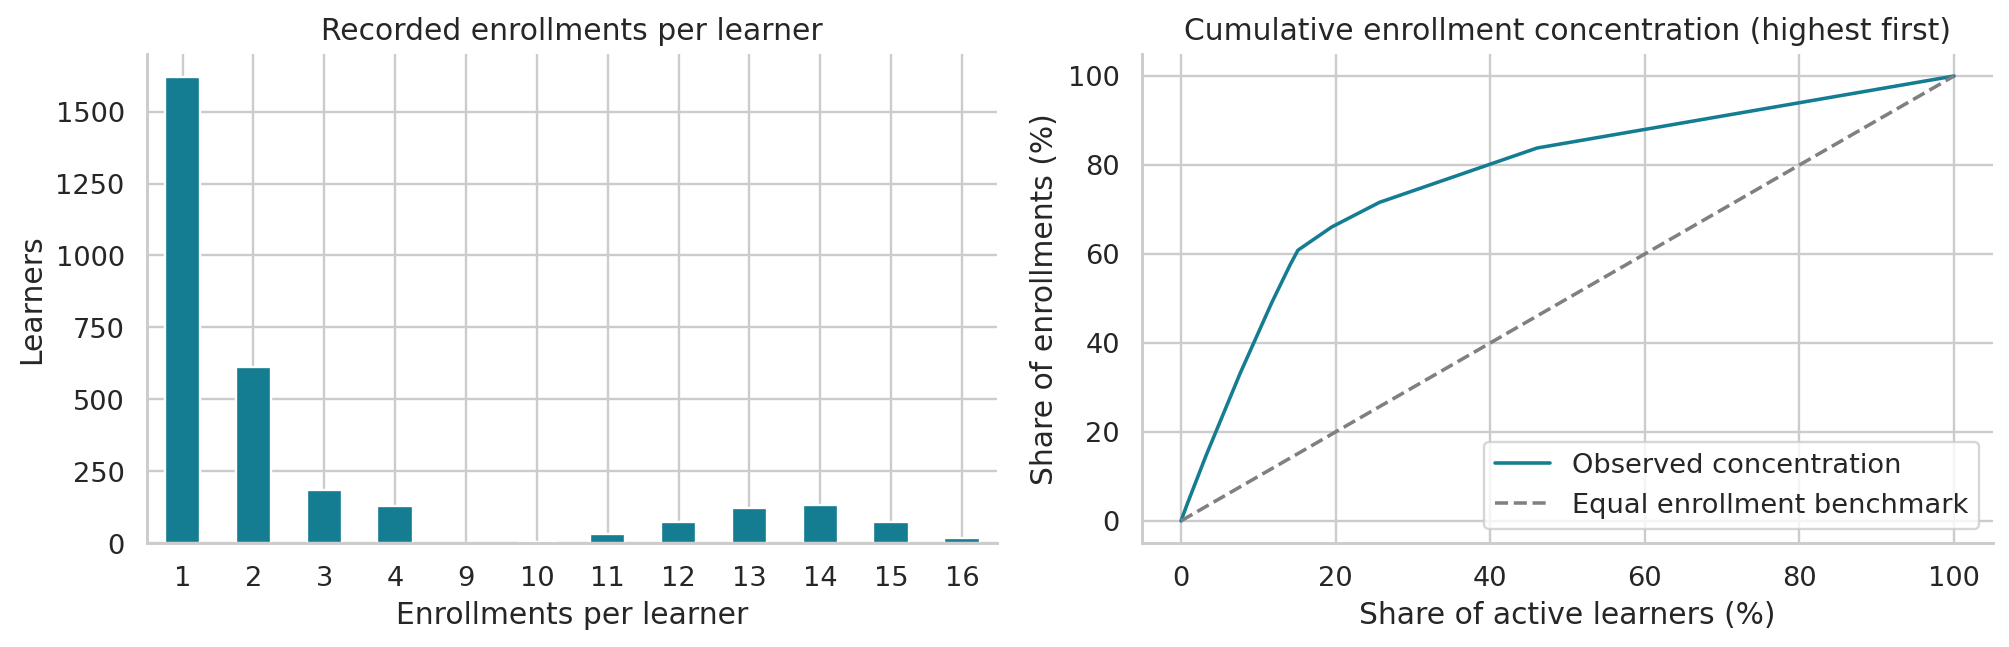

In [9]:
activity_distribution = learner_counts.value_counts().sort_index().rename_axis('EnrollmentsPerLearner').to_frame('Learners')
activity_distribution['ShareOfLearnersPct']=activity_distribution.Learners/len(users)*100
save_table(activity_distribution,'activity_distribution')
concentration=[]
for pct in [1,5,10,20,50]:
    n=math.ceil(pct/100*len(active_counts))
    concentration.append({'TopActiveLearnersPct':pct,'Learners':n,'Enrollments':active_counts.iloc[:n].sum(),'EnrollmentSharePct':active_counts.iloc[:n].sum()/len(enrollments)*100})
concentration=pd.DataFrame(concentration).set_index('TopActiveLearnersPct')
save_table(concentration,'enrollment_concentration')
fig,axs=plt.subplots(1,2,figsize=(12,4))
activity_distribution.Learners.plot.bar(ax=axs[0],color='#147D92',rot=0)
axs[0].set(title='Recorded enrollments per learner',xlabel='Enrollments per learner',ylabel='Learners')
x=np.arange(1,len(active_counts)+1)/len(active_counts)*100
y=active_counts.cumsum().to_numpy()/len(enrollments)*100
axs[1].plot(np.r_[0,x],np.r_[0,y],color='#147D92',label='Observed concentration')
axs[1].plot([0,100],[0,100],'--',color='gray',label='Equal enrollment benchmark')
axs[1].set(title='Cumulative enrollment concentration (highest first)',xlabel='Share of active learners (%)',ylabel='Share of enrollments (%)')
axs[1].legend()
show_chart('09_activity_concentration')

## Step 10 — Export reusable tables and summarize findings
Descriptive observations are not causal effects or formal statistical tests.
No external research, predictions or monetization analysis is required.

In [10]:
with pd.ExcelWriter(OUT/'edupro_summary_tables.xlsx',engine='openpyxl') as writer:
    for path in sorted(TABLES.glob('*.csv')):
        pd.read_csv(path).to_excel(writer,sheet_name=path.stem[:31],index=False)
print('KEY FINDINGS')
print(f'{len(enrollments):,} transactions; {len(users):,} registered/active learners; mean {learner_counts.mean():.2f} and median {learner_counts.median():.0f} enrollments.')
print('Largest age group by enrollment: 26–35; highest per-learner rate: <18.')
print('Data Science leads category demand; Marketing and Programming tie for lowest.')
print(f'Top {top_n} active learners account for {active_counts.iloc[:top_n].sum()/len(enrollments)*100:.2f}% of enrollment.')
print('Limitations: one transaction period; no completion/outcome/skill data; no learners over 35; recorded course metadata may need review.')
print('All aggregate tables, charts and the Excel summary workbook were generated successfully.')

KEY FINDINGS
10,000 transactions; 3,000 registered/active learners; mean 3.33 and median 1 enrollments.
Largest age group by enrollment: 26–35; highest per-learner rate: <18.
Data Science leads category demand; Marketing and Programming tie for lowest.
Top 300 active learners account for 42.34% of enrollment.
Limitations: one transaction period; no completion/outcome/skill data; no learners over 35; recorded course metadata may need review.
All aggregate tables, charts and the Excel summary workbook were generated successfully.
